In [134]:
import pandas as pd
from tqdm import tqdm
import seaborn as sns

In [135]:
all_types=pd.read_pickle("./clear-fusion_tama_augustus.pkl")

In [136]:
gene_template={'alternative_3end5end':0,
        'at_least_one_novel_splicesite':0,
        'alternative_3end':0,
        'intron_retention':0,
        'mono-exon':0,
        '3prime_fragment':0,
        'multi-exon':0,
        '5prime_fragment':0,
        'combination_of_known_splicesites':0,
        'reference_match':0,
        'alternative_5end':0,
        'internal_fragment':0,
        'mono-exon_by_intron_retention':0,
        'combination_of_known_junctions':0,
        'fusion':0}

In [137]:
weights={'reference_match':0.05,
         'alternative_3end':0.1,
         'alternative_5end':0.1,
         'alternative_3end5end':0.1,
         'combination_of_known_splicesites':0.2,
         'combination_of_known_junctions':0.2,
         '3prime_fragment':0.3,
         '5prime_fragment':0.3,
         'internal_fragment':0.3,
         'mono-exon':0.15,
         'multi-exon':0.15,
         'mono-exon_by_intron_retention':0.2,
         'fusion':0.5,
         'at_least_one_novel_splicesite':0.5,
         'intron_retention':0.5,}

1) The ORF is calculated with the Shannon Entropy, explaining the total information content of the gene. The relation of different alternative splicing events (AS-events) to the resulting open reading frames (ORFs) is the key part of gene vaiability based on isoforms. One advantage of this method is the resulting value of 0 if only one open reading frame is found. This means zero variability in the gene, even though a variety of different alternative splicing (AS) events are found:

    Let $o_i$ be the number of occurences of ORF $i$ in a gene with $n$ different reported ORFs and $m$ total isoforms.

$$ORFscore = -\sum_{i = 1}^{n} {o_i \over m} * {\log {o_i \over m}}$$

2) In a wider extend, gene variability not only includes the number of isoforms and ORFs, but also AS events leading to the ORFs and the the impact of an AS event on protein structure after translation. The variability of the first two events is covered by the $ORFscore$, while the latter ones are adressed differently:
    The first task is to identify gene loci with specific AS events happening more frequently than in others. Assigning simple score based on the number of event-categories do fit here. For every AS event $i$ in a gene, compute the relative frequency within the gene with respect to the total amount of isoforms $m$: 
$$freq_i ={n_i  \over m}$$ 

3) To account for the impact on protein structure, a general score to summarize the category variability is introduced. Each of the AS events an have a differing effect on translation and thus, the means are weighted. The logic of these (so far arbitrary chosen) weights is as follows:\
    Low (0-0.1): We used AUGUSTUS annotations lacking UTRs, so we expect these categories enriched in our analysis (Data show this!), weights are low. Same for reference matches since they add even less variability.\
    Low (0.15): From Luisa: Mono and multi exons within the gene, but with non-matching splice junctions are likely some randomness and not too meaningful.\
    Medium (0.2): Combination of known splice sites and junctions do add variability, but are just combining prior knowledge and are less likely (?) to mess with total protein structure. Mono-exons by intron retention form a different case compared to the mono/multi-exons as desctibe before. Here, two or more exons are fused, but have known and valid 5'/3' splice junctions.\
    Medium (0.3-0.4): This section describes the ISM section of SQANTI, in which complete parts of a gene are missing. From fragments at the 3' and/or 5' ends up to only a mono exon or multiple ones, whole domains could be missing in the later protein (RPP7 with FPA)\
    High (0.5+): Intron retention can add a several things to a gene, including stop codons, frameshifts etc. This also is true for fusion genes, basically being an intergenic retention. Since AUGUSTUS predicts genes based on patterns in sequence, novel splicing sites are quite interesting, since non-canonical splice sites exist and they add quite a bit of "unusual" variability.
    
    Let $freq_i$ be the relative frequency of a specific AS event $i$ out of $n$ AS event-categories (see gene template) and $w_i$ the assigned weight, calculate the weighted mean as follows:
$$EVENTscore = {\sum_{i = 1}^{n} freq_i * w_i \over \sum_{i = 1}^{n} w_i}$$

4) VARscore: Last, take the product of the $ORFscore$ and the $EVENTscore$ to "normalize" the weighted mean with the general information content. This results in a score, combining all variability metrics described in 2:

$$VARscore = ORFscore * EVENTscore$$

5) Comment: One issue I could see here is that the weighted mean turns to 1 if only one AS is present. On the other hand, this gives a reason to "normalize" by the Shanon Entropy again, as a ration of 1 AS event to 1 ORF would turn to 0 again. If more ORFs are present, the variability score of the ORFs is multiplied by 1, giving high variability most likely. 

In [138]:
#v3 (weigthed mean)
import math
from scipy.stats import entropy
import numpy as np

def iso_var(df):
    df=df.copy()
    # get n isoforms per gene
    isoforms=len(df["isoform"].tolist())
    # get n orfs per gene
    orfs=len(set(df["Sqanti_ORF_seq"].tolist()))

    ###--------------------------------------###
    ### get n isoforms per ORF (-->ORF score)###
    # include NA, since they are noncoding
    df["isoforms_per_orf"]=df.groupby(by=["Sqanti_ORF_seq"], dropna=False)["isoform"].transform(lambda x: len(x.tolist()))
    iso_per_orf=[]
    for orf in df.groupby("Sqanti_ORF_seq", dropna=False):
        iso_per_orf.append(orf[1]["isoforms_per_orf"].unique().item())
    # get chance of finding an ORF
    ratio=iso_per_orf/np.sum(iso_per_orf)
    # absolute values of the log: take log, since we will never get above 1. 
    # And if you have 1, there is no variability since all Isoforms encode the same ORF.
    # This could be an issue if you want to look at 3'5' differences...

    ## Test1
    #log = np.log(ratio) #google shannon entropy in python    
    # variability score of orf distribution:
    #orf_val = -(np.sum(log))

    ## Shannon entropy
    orf_val = entropy(ratio)


    ###--------------------------------------###
    ### get Category Score
    # split clear cases and fusion genes:
    c=df[~(df["structural_category"]=="fusion")]
    f=df[df["structural_category"]=="fusion"]
    #create out_df
    out_df=pd.DataFrame([gene_template])
    
    ## handle clear cases:
    occ=dict(c["subcategory"].value_counts())
    # weighted mean metrics
    num = 0
    den = 0
    
    for cat in occ.keys():
        # get frequency
        cat_val=occ[cat]/isoforms
        # fill df
        out_df[cat] = [cat_val]
        # and save the frequency*weight + weight for weighted mean calculation
        num = occ[cat]*weights[cat]/isoforms
        den = weights[cat]

    # add fusion isoforms (relative frequency)
    if len(f) > 0:
        out_df["fusion"]=[len(f)/isoforms]
        num += (len(f)*weights["fusion"])/isoforms
        den += weights["fusion"]
        
    # CAT score (weighted mean):
    out_df["cat_score"] = [num/den]
    
    # add ORF score
    out_df["orf_score"] = orf_val
    
    #fill na
    out_df.fillna(0,inplace=True)
    
    # multiply the category variability score with the variability score of the ORFs
    out_df["var_score"]= out_df["cat_score"]*orf_val

    return out_df

In [139]:
var_scores_all=pd.DataFrame()
for acc in tqdm(all_types["accession"].unique().tolist()):
    
    nlr_acc=all_types.loc[(all_types["accession"]==f"{acc}")].copy()
    acc_var=pd.DataFrame()
    
    #nlr_acc=all_types.loc[(all_types["accession"]==f"{acc}")&(all_types["type"]=="nlr")].copy()
    for i in nlr_acc.groupby(by="gene", as_index=False):
        gene_var=iso_var(i[1])
        gene_var["gene"]=i[0]
        if "nlr" in i[1]["type"].tolist():
            gene_var["type"]="nlr"
        else:
            gene_var["type"]="other"
        acc_var=pd.concat([acc_var, gene_var])
    #acc_df=pd.DataFrame({"value":acc_var, "gene":acc_gene, "type":acc_type})
    acc_var["accession"]=acc
    var_scores_all=pd.concat([var_scores_all, acc_var]).fillna(0)
    #print(nlr_acc.groupby(by="gene", as_index=False))

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 18/18 [25:26<00:00, 84.82s/it]


In [149]:
all_types.loc[(all_types["accession"]=="at6923")&(all_types["gene"]=="G1")]

,gene,isoform,accession,associated_gene,associated_transcript,exons,length,isoform_read_support,gene_read_support,structural_category,subcategory,Sqanti_ORF_seq,cat_assign,association,cat_read_support,gene_association_read_support,type,isoforms_per_gene,ORFs_per_gene,isoforms_per_ORFs
825532,G1,G1.1,at6923,g1,g1.t1,6,1663,1,2,full-splice_match,alternative_3end5end,MEDQVGFGFRPNDEELVGHYLRNKIEGNTSRDVEVAISEVNICSYD...,one2one,1,2,2,other,2,1,2.0
825533,G1,G1.2,at6923,g1,g1.t1,6,1588,1,2,full-splice_match,alternative_3end5end,MEDQVGFGFRPNDEELVGHYLRNKIEGNTSRDVEVAISEVNICSYD...,one2one,1,2,2,other,2,1,2.0


In [150]:
at9900=var_scores_all.loc[(var_scores_all["accession"]=="at9900")]

In [151]:
s=['alternative_3end5end', 'at_least_one_novel_splicesite',
       'alternative_3end', 'intron_retention', 'mono-exon', '3prime_fragment',
       'multi-exon', '5prime_fragment', 'combination_of_known_splicesites',
       'reference_match', 'alternative_5end', 'internal_fragment',
       'mono-exon_by_intron_retention', 'combination_of_known_junctions',
       'fusion', 'cat_score']

In [152]:
at9900_dup_cat=at9900.loc[(at9900.duplicated(subset=s))& (at9900["var_score"]!=0)]

In [153]:
at9900.loc[(at9900["cat_score"].astype("int") !=1)]

,alternative_3end5end,at_least_one_novel_splicesite,alternative_3end,intron_retention,mono-exon,3prime_fragment,multi-exon,5prime_fragment,combination_of_known_splicesites,reference_match,...,internal_fragment,mono-exon_by_intron_retention,combination_of_known_junctions,fusion,cat_score,orf_score,var_score,gene,type,accession
0,0.500000,0.500000,0.000000,0.00000,0.000000,0.000000,0.0000,0.0,0.0,0.0,...,0.00,0.0,0.0,0.0000,0.500000,0.693147,0.346574,G10,other,at9900
0,0.062500,0.468750,0.062500,0.09375,0.031250,0.031250,0.1875,0.0,0.0,0.0,...,0.00,0.0,0.0,0.0625,0.055288,1.276720,0.070588,G100,other,at9900
0,0.175000,0.125000,0.000000,0.00000,0.000000,0.550000,0.0000,0.1,0.0,0.0,...,0.05,0.0,0.0,0.0000,0.050000,2.943407,0.147170,G10001,other,at9900
0,0.500000,0.000000,0.166667,0.00000,0.166667,0.166667,0.0000,0.0,0.0,0.0,...,0.00,0.0,0.0,0.0000,0.166667,0.000000,0.000000,G10002,other,at9900
0,0.000000,0.833333,0.000000,0.00000,0.000000,0.166667,0.0000,0.0,0.0,0.0,...,0.00,0.0,0.0,0.0000,0.166667,0.450561,0.075094,G10004,other,at9900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
0,0.666667,0.333333,0.000000,0.00000,0.000000,0.000000,0.0000,0.0,0.0,0.0,...,0.00,0.0,0.0,0.0000,0.333333,0.636514,0.212171,G999,other,at9900
0,0.000000,0.800000,0.000000,0.20000,0.000000,0.000000,0.0000,0.0,0.0,0.0,...,0.00,0.0,0.0,0.0000,0.200000,0.500402,0.100080,G9990,other,at9900
0,0.666667,0.000000,0.083333,0.00000,0.000000,0.250000,0.0000,0.0,0.0,0.0,...,0.00,0.0,0.0,0.0000,0.083333,0.823959,0.068663,G9991,other,at9900
0,0.500000,0.000000,0.000000,0.00000,0.000000,0.000000,0.0000,0.5,0.0,0.0,...,0.00,0.0,0.0,0.0000,0.500000,0.693147,0.346574,G9994,other,at9900


In [154]:
at9900["cat_score"].dtype

dtype('float64')

In [155]:
at9900_dup_cat.drop_duplicates(subset=s).sort_values(by=s, ascending=False)

,alternative_3end5end,at_least_one_novel_splicesite,alternative_3end,intron_retention,mono-exon,3prime_fragment,multi-exon,5prime_fragment,combination_of_known_splicesites,reference_match,...,internal_fragment,mono-exon_by_intron_retention,combination_of_known_junctions,fusion,cat_score,orf_score,var_score,gene,type,accession
0,1.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.000000,0.450561,0.450561,G10293,other,at9900
0,1.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.000000,0.410116,0.410116,G10182,other,at9900
0,0.947368,0.0,0.000000,0.052632,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.052632,0.206192,0.010852,G13640,other,at9900
0,0.944444,0.0,0.055556,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.055556,0.214559,0.011920,G5069,other,at9900
0,0.944444,0.0,0.000000,0.055556,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.055556,0.214559,0.011920,G16200,other,at9900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
0,0.000000,0.0,0.000000,0.000000,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.000000,0.655976,0.655976,G10390,other,at9900
0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.000000,0.450561,0.450561,G2714,nlr,at9900
0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.000000,0.450561,0.450561,G15576,other,at9900
0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.000000,0.970585,0.970585,G12871,other,at9900


In [156]:
at9900_dup_cat.sort_values(by=s, ascending=False)

,alternative_3end5end,at_least_one_novel_splicesite,alternative_3end,intron_retention,mono-exon,3prime_fragment,multi-exon,5prime_fragment,combination_of_known_splicesites,reference_match,...,internal_fragment,mono-exon_by_intron_retention,combination_of_known_junctions,fusion,cat_score,orf_score,var_score,gene,type,accession
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.450561,0.450561,G10293,other,at9900
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.636514,0.636514,G103,other,at9900
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.636514,0.636514,G10941,other,at9900
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.286836,0.286836,G11967,other,at9900
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.636514,0.636514,G12490,other,at9900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.682908,0.682908,G6756,other,at9900
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.500402,0.500402,G7082,other,at9900
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.500402,0.500402,G7352,other,at9900
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.636514,0.636514,G8154,other,at9900


In [157]:
s2=['alternative_3end5end', 'at_least_one_novel_splicesite',
       'alternative_3end', 'intron_retention', 'mono-exon', '3prime_fragment',
       'multi-exon', '5prime_fragment', 'combination_of_known_splicesites',
       'reference_match', 'alternative_5end', 'internal_fragment',
       'mono-exon_by_intron_retention', 'combination_of_known_junctions',
       'fusion', 'cat_score', 'orf_score', 'var_]

SyntaxError: unterminated string literal (detected at line 6) (2193752539.py, line 6)

In [158]:
at9900_dup_cat.loc[at9900_dup_cat=at9900.loc[(at9900.duplicated(subset=s2))]]

SyntaxError: invalid syntax. Maybe you meant '==' or ':=' instead of '='? (1438457392.py, line 1)

In [159]:
['alternative_3end5end', 'at_least_one_novel_splicesite',
       'alternative_3end', 'intron_retention', 'mono-exon', '3prime_fragment',
       'multi-exon', '5prime_fragment', 'combination_of_known_splicesites',
       'reference_match', 'alternative_5end', 'internal_fragment',
       'mono-exon_by_intron_retention', 'combination_of_known_junctions',
       'fusion', 'cat_score', 'orf_score', 'var_score', 'gene', 'type',
       'accession']

['alternative_3end5end',
 'at_least_one_novel_splicesite',
 'alternative_3end',
 'intron_retention',
 'mono-exon',
 '3prime_fragment',
 'multi-exon',
 '5prime_fragment',
 'combination_of_known_splicesites',
 'reference_match',
 'alternative_5end',
 'internal_fragment',
 'mono-exon_by_intron_retention',
 'combination_of_known_junctions',
 'fusion',
 'cat_score',
 'orf_score',
 'var_score',
 'gene',
 'type',
 'accession']

In [160]:
var_scores_all

,alternative_3end5end,at_least_one_novel_splicesite,alternative_3end,intron_retention,mono-exon,3prime_fragment,multi-exon,5prime_fragment,combination_of_known_splicesites,reference_match,...,internal_fragment,mono-exon_by_intron_retention,combination_of_known_junctions,fusion,cat_score,orf_score,var_score,gene,type,accession
0,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00,0.000,0.0,0.000000,...,0.0,0.0,0.0,0.0,1.000000,0.000000,0.000000,G1,other,at6923
0,0.500000,0.045455,0.227273,0.045455,0.090909,0.090909,0.00,0.000,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.045455,1.031820,0.046901,G10,other,at6923
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.00,0.000,0.0,0.000000,...,0.0,0.0,0.0,0.0,1.000000,0.000000,0.000000,G100,other,at6923
0,0.333333,0.083333,0.416667,0.166667,0.000000,0.000000,0.00,0.000,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.083333,1.118743,0.093229,G1000,other,at6923
0,0.000000,0.000000,0.000000,0.000000,0.250000,0.000000,0.75,0.000,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.250000,0.661563,0.165391,G10000,other,at6923
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
0,0.025000,0.125000,0.025000,0.000000,0.025000,0.350000,0.00,0.025,0.0,0.150000,...,0.0,0.0,0.0,0.0,0.025000,1.651755,0.041294,G9995,other,col0
0,0.088235,0.088235,0.352941,0.000000,0.000000,0.000000,0.00,0.000,0.0,0.264706,...,0.0,0.0,0.0,0.0,0.088235,0.395372,0.034886,G9996,other,col0
0,0.000000,0.000000,0.166667,0.166667,0.000000,0.000000,0.00,0.000,0.0,0.500000,...,0.0,0.0,0.0,0.0,0.166667,0.867563,0.144594,G9997,other,col0
0,0.000000,0.000000,0.166667,0.166667,0.000000,0.000000,0.00,0.000,0.0,0.500000,...,0.0,0.0,0.0,0.0,0.166667,0.450561,0.075094,G9998,other,col0


In [161]:
import matplotlib.pylab as plt

<AxesSubplot:xlabel='accession', ylabel='var_score'>

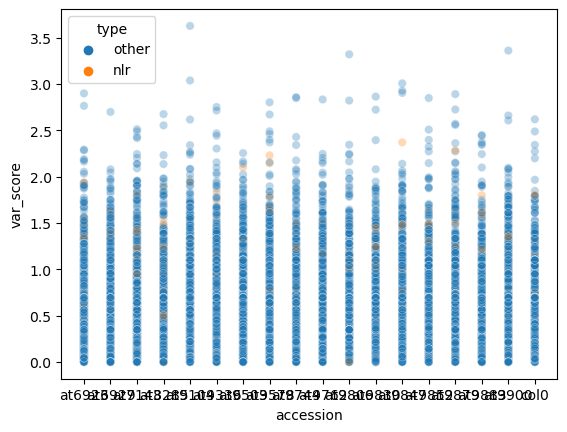

In [162]:
sns.scatterplot(data=var_scores_all, x="accession", y="var_score", hue="type", alpha=0.3)

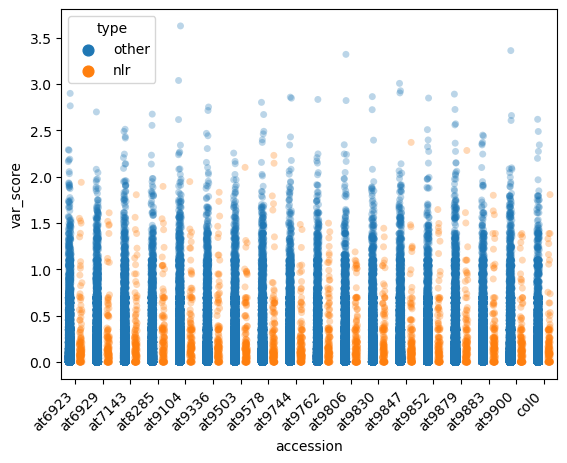

In [163]:
#sns.set_palette(sns.color_palette("colorblind"))
sns.stripplot(data=var_scores_all, x="accession", y="var_score", hue="type", alpha=0.3, hue_order=["other","nlr"], dodge=True)

plt.xticks(rotation=45,horizontalalignment='right')
plt.savefig("var_score_accession.png")

<AxesSubplot:xlabel='accession', ylabel='var_score'>

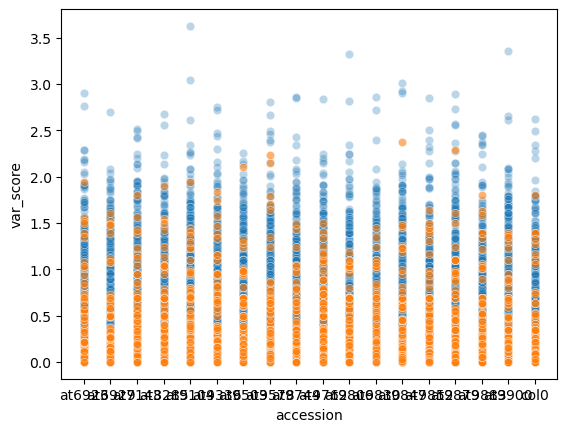

In [164]:
sns.scatterplot(data=var_scores_all.loc[var_scores_all["type"]=="other"], x="accession", y="var_score", alpha=0.3)
sns.scatterplot(data=var_scores_all.loc[var_scores_all["type"]=="nlr"], x="accession", y="var_score", alpha=0.6)


In [165]:
#9847 G11520

In [210]:
gene=all_types[(all_types["type"]=="nlr")&(all_types["accession"]=="at6923")]

In [775]:
v=[]
for g in gene["gene"].unique():
    df=gene[gene["gene"]==g]
    v.append(iso_var(df))

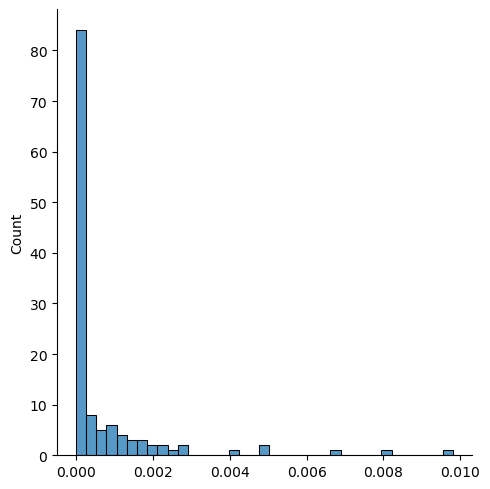

In [776]:
sns.displot(v)

In [141]:
#v1

import numpy as np

def iso_var(df):
    df=df.copy()
    # get n isoforms per gene
    isoforms=len(df["isoform"].tolist())
    # get n orfs per gene
    orfs=len(set(df["Sqanti_ORF_seq"].tolist()))
    
    ###--------------------------------------###
    ### get n isoforms per ORF (-->ORF score)###
    # include NA, since they are noncoding
    df["isoforms_per_orf"]=df.groupby(by=["Sqanti_ORF_seq"], dropna=False)["isoform"].transform(lambda x: len(x.tolist()))
    iso_per_orf=[]
    for orf in df.groupby("Sqanti_ORF_seq", dropna=False):
        iso_per_orf.append(orf[1]["isoforms_per_orf"].unique().item())
    # get chance of finding an ORF
    ratio=iso_per_orf/np.sum(iso_per_orf)
    # absolute values of the log: take log, since we will never get above 1. 
    # And if you have 1, there is no variability since all Isoforms encode the same ORF.
    # This could be an issue if you want to look at 3'5' differences...
    abs_log = abs(np.log(ratio))
    # variability score of orf distribution (*0.1 to scale the values down):
    orf_val = np.prod(abs_log*0.1)

    
    ###--------------------------------------###
    ### get Category Score
    # split clear cases and fusion genes:
    c=df[~(df["structural_category"]=="fusion")]
    f=df[df["structural_category"]=="fusion"]
    
    # fill clear cases dict
    occ=dict(c["subcategory"].value_counts())
    cat_val=0
    for cat in occ.keys():
        cat_val+=occ[cat]*weights[cat]
    
    # add fusion isoforms (relative frequency)
    cat_val+=len(f)*weights["fusion"]
    
    ###
    # In theory, one should extract nc clear cases and fusions isoforms first and let them contribute in a lower frequency since they add less variability?
    # On the other hand, they are also valid isoforms contributing to the variability of the gene, so I left it for now. Input required
    
    # multiply the category variability score with the variability score of the ORFs
    score = cat_val*orf_val
    
    # Don't know if we need it... we have handeled the ORF/isoform ratios already:
    # divide the number of orfs by the number of isoforms, approaching 1. 
    # The lower the amount of orfs, the smaller the final socre will be
    #cat_norm = cat_val*(orfs/isoforms)
    #score = cat_norm*orf_val
    
    return score

In [25]:
# v2
from scipy.stats import entropy
import numpy as np

def iso_var(df):
    df=df.copy()
    # get n isoforms per gene
    isoforms=len(df["isoform"].tolist())
    # get n orfs per gene
    orfs=len(set(df["Sqanti_ORF_seq"].tolist()))
    
    ###--------------------------------------###
    ### get n isoforms per ORF (-->ORF score)###
    # include NA, since they are noncoding
    df["isoforms_per_orf"]=df.groupby(by=["Sqanti_ORF_seq"], dropna=False)["isoform"].transform(lambda x: len(x.tolist()))
    iso_per_orf=[]
    for orf in df.groupby("Sqanti_ORF_seq", dropna=False):
        iso_per_orf.append(orf[1]["isoforms_per_orf"].unique().item())
    # get chance of finding an ORF
    ratio=iso_per_orf/np.sum(iso_per_orf)
    # absolute values of the log: take log, since we will never get above 1. 
    # And if you have 1, there is no variability since all Isoforms encode the same ORF.
    # This could be an issue if you want to look at 3'5' differences...
    
    ## Test1
    #log = np.log(ratio) #google shannon entropy in python    
    # variability score of orf distribution:
    #orf_val = -(np.sum(log))
    
    ## Shannon entropy
    orf_val = entropy(ratio)

    
    ###--------------------------------------###
    ### get Category Score
    # split clear cases and fusion genes:
    c=df[~(df["structural_category"]=="fusion")]
    f=df[df["structural_category"]=="fusion"]
    
    # fill clear cases dict
    occ=dict(c["subcategory"].value_counts())
    cat_val=0
    for cat in occ.keys():
        cat_val+=(occ[cat]*weights[cat])/isoforms
    
    # add fusion isoforms (relative frequency)
    cat_val+=(len(f)*weights["fusion"])/isoforms
    
    # multiply the category variability score with the variability score of the ORFs
    score = cat_val*orf_val
    
    return score

In [26]:
var_scores_all=pd.DataFrame()
for acc in all_types["accession"].unique().tolist():
    acc_var=[]
    acc_gene=[]
    acc_type=[]
    nlr_acc=all_types.loc[(all_types["accession"]==f"{acc}")].copy()

    #nlr_acc=all_types.loc[(all_types["accession"]==f"{acc}")&(all_types["type"]=="nlr")].copy()
    for i in nlr_acc.groupby(by="gene", as_index=False):
        acc_var.append(iso_var(i[1]))
        acc_gene.append(i[0])
        if "nlr" in i[1]["type"].tolist():
            acc_type.append("nlr")
        else:
            acc_type.append("other")
    acc_df=pd.DataFrame({"value":acc_var, "gene":acc_gene, "type":acc_type})
    acc_df["accession"]=acc
    var_scores_all=pd.concat([var_scores_all, acc_df])
    #print(nlr_acc.groupby(by="gene", as_index=False))

In [27]:
var_scores_all

,value,gene,type,accession
0,0.000000,G1,other,at6923
1,0.103182,G10,other,at6923
2,0.000000,G100,other,at6923
3,0.111874,G1000,other,at6923
4,0.066156,G10000,other,at6923
...,...,...,...,...
15626,0.165175,G9995,other,col0
15627,0.039537,G9996,other,col0
15628,0.086756,G9997,other,col0
15629,0.045056,G9998,other,col0


# For TEs

In [166]:
var_scores_9762=var_scores_all.loc[var_scores_all["accession"]=="at9762"]


In [178]:
var_scores_TE=var_scores_9762.loc[(var_scores_9762["alternative_3end"]>0)|(var_scores_9762["3prime_fragment"]>0)|(var_scores_9762["alternative_3end5end"]>0)|(var_scores_9762["alternative_5end"]>0)|(var_scores_9762["internal_fragment"]>0)|(var_scores_9762["intron_retention"]>0)]

In [179]:
var_scores_TE

,alternative_3end5end,at_least_one_novel_splicesite,alternative_3end,intron_retention,mono-exon,3prime_fragment,multi-exon,5prime_fragment,combination_of_known_splicesites,reference_match,...,internal_fragment,mono-exon_by_intron_retention,combination_of_known_junctions,fusion,cat_score,orf_score,var_score,gene,type,accession
0,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.000000,1.000000,0.000000,0.000000,G1,other,at9762
0,0.333333,0.333333,0.000000,0.333333,0.000000,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.333333,1.098612,0.366204,G10,other,at9762
0,0.722222,0.000000,0.111111,0.000000,0.166667,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.111111,0.760755,0.084528,G1000,other,at9762
0,0.646154,0.076923,0.138462,0.076923,0.000000,0.015385,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.046154,0.034615,1.644542,0.056926,G10000,other,at9762
0,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.000000,1.000000,0.000000,0.000000,G10002,other,at9762
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
0,0.000000,0.705882,0.000000,0.235294,0.000000,0.000000,0.0,0.058824,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.058824,1.579233,0.092896,G9993,other,at9762
0,0.666667,0.166667,0.166667,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.166667,0.867563,0.144594,G9994,other,at9762
0,0.400000,0.400000,0.000000,0.000000,0.000000,0.200000,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.200000,0.500402,0.100080,G9995,other,at9762
0,0.333333,0.000000,0.000000,0.000000,0.166667,0.333333,0.0,0.166667,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.166667,1.560710,0.260118,G9996,other,at9762


In [188]:
sqanti=all_types.loc[(all_types["gene"].isin(var_scores_TE["gene"]))&(all_types["accession"]=="at9762")][["gene","associated_gene"]].drop_duplicates()

In [211]:
augustus_genes=pd.DataFrame()
for i in sqanti.groupby("gene"):
    sq=i[0]
    aug=i[1]["associated_gene"].tolist()
    g=pd.DataFrame({"gene":sq,"augustus_gene":[aug]})
    augustus_genes=pd.concat([augustus_genes, g])
augustus_genes

,gene,augustus_gene
0,G1,[g1]
0,G10,[g11]
0,G1000,[g1517]
0,G10000,"[g20050, g20049_g20050, g20049]"
0,G10002,[g20053]
...,...,...
0,G9993,[g20041]
0,G9994,[g20042]
0,G9995,[g20043]
0,G9996,[g20044]


In [218]:
Adri_TE = pd.merge(var_scores_TE, augustus_genes, on="gene")

In [219]:
Adri_TE=Adri_TE.explode("augustus_gene")

In [ ]:
Adri_TE.to_csv("/tmp/global2/acontreras/Col-0_ISOSEQ/SRR_dataset/")